# Merging IPCEI firms to LinkedIn network


#### 1. Set-up

In [1]:
import os
import pandas as pd

# Set working directory
WORKING_DIR = "/Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/src/data/raw/linkedin"
os.chdir(WORKING_DIR)

In [ ]:
# Load all datasets
orgs_df = pd.read_csv("organizations_linkedin.csv")
collab_df = pd.read_csv("innovation_network_prepost_2020-01-01.csv")
ipcei_df = pd.read_csv("IPCEI_firms_linkedin.csv")

In [2]:
orgs_df

,Linkedin_name,name,website,country,firm_type,sector,industry
0,first-priority-group,First Priority Group,http://www.1fpg.com,US,Manufacturer,"Electric Vehicles, Other Transport",Motor Vehicle Manufacturing
1,machadomeyer,"Machado, Meyer, Sendacz e Opice Advogados",http://www.machadomeyer.com.br,BR,Service Provider,Other Sectors,Law Practice
2,2g-energy-inc,2G Energy North America,http://www.2g-energy.com,US,Manufacturer,"Biogas, Hydrogen, Other Manufacturing",Renewable Energy Semiconductor Manufacturing
3,3ts-capital-partners,3TS Capital Partners,http://www.3tscapital.com,AT,Venture Capital,Other Sectors,Venture Capital and Private Equity Principals
4,biovia,BIOVIA,http://www.3DS.com/BIOVIA,US,Service Provider,"Software, Other Manufacturing",Software Development
...,...,...,...,...,...,...,...
148955,teko-refrigeration,TEKO Refrigeration,http://www.teko-gmbh.com,DE,Manufacturer,Other Sectors,Industrial Machinery Manufacturing
148956,onsagers-as,Onsagers AS,http://www.onsagers.no,NO,Service Provider,Other Sectors,Law Practice
148957,ivadolabs,IVADO Labs,http://ivadolabs.com/en/,CA,Service Provider,Other ICT,IT Services and IT Consulting
148958,catch-foundation-ngo-working-for-environment-p...,Catch Foundation : NGO Working For Environment...,https://catchfoundation.in,IN,Non Governmental Organization,Other Sectors,Environmental Services


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_88189/1613044673.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")


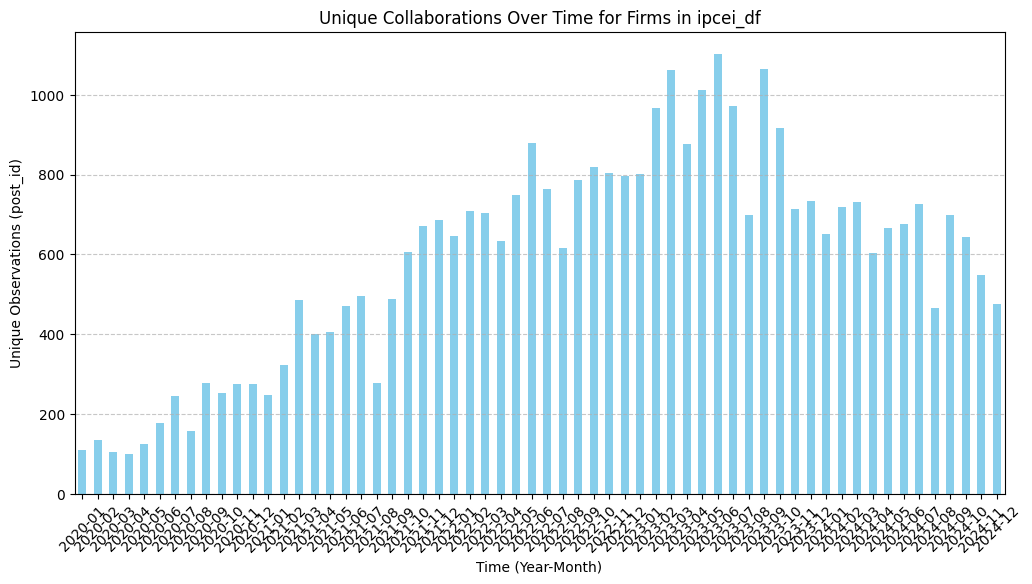

In [3]:
import matplotlib.pyplot as plt

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = ipcei_df["Linkedin_name"].dropna().unique()

# ✅ Step 2: Filter collab_df where either "source" or "target" is in firms_with_linkedin
filtered_collab_df = collab_df[
    (collab_df["source"].isin(firms_with_linkedin)) |
    (collab_df["target"].isin(firms_with_linkedin))
]

# ✅ Step 3: Ensure "post_date" is in datetime format and remove duplicate post_ids
filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")

# Drop duplicate post_ids to ensure uniqueness
filtered_collab_df = filtered_collab_df.drop_duplicates(subset=["post_id"])

# ✅ Step 4: Aggregate unique post occurrences per month
unique_posts_over_time = filtered_collab_df.groupby(filtered_collab_df["post_date"].dt.to_period("M"))["post_id"].nunique()

# ✅ Step 5: Plot the unique observations over time
plt.figure(figsize=(12, 6))
unique_posts_over_time.plot(kind="bar", color="skyblue")
plt.xlabel("Time (Year-Month)")
plt.ylabel("Unique Observations (post_id)")
plt.title("Unique Collaborations Over Time for Firms in ipcei_df")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()


Check how many IPCEI firms can be matched to the collab data

In [5]:
import pandas as pd

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = set(ipcei_df["Linkedin_name"].dropna().unique())

# ✅ Step 2: Extract unique firms from collab_df in "source" and "target"
firms_in_collab = set(collab_df["source"].dropna().unique()).union(set(collab_df["target"].dropna().unique()))

# ✅ Step 3: Identify firms in ipcei_df that are matched in collab_df
matched_firms = firms_with_linkedin.intersection(firms_in_collab)
unmatched_firms = firms_with_linkedin - firms_in_collab

# ✅ Step 4: Count the number of matched and unmatched firms
matched_count = len(matched_firms)
unmatched_count = len(unmatched_firms)

# ✅ Step 5: Create a summary table
summary_df = pd.DataFrame({
    "Category": ["Matched Firms", "Unmatched Firms"],
    "Count": [matched_count, unmatched_count]
})

# 📌 Print the summary table
print(summary_df)
# 50 are not matched

# ✅ Optional: Save the summary to a CSV file
summary_df.to_csv("matching_summary.csv", index=False)
print("✅ Summary saved as 'matching_summary.csv'.")

# ✅ Optional: Save unmatched firms for review
unmatched_firms_df = pd.DataFrame(unmatched_firms, columns=["Unmatched_Linkedin_name"])
unmatched_firms_df.to_csv("unmatched_firms.csv", index=False)
print("✅ Unmatched firms saved as 'unmatched_firms.csv'.")


          Category  Count
0    Matched Firms    178
1  Unmatched Firms     48
✅ Summary saved as 'matching_summary.csv'.
✅ Unmatched firms saved as 'unmatched_firms.csv'.


Plot the development of collabs over time by IPCEI type

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
from datetime import datetime

# =======================
# 0) INPUTS: ipcei_df, collab_df
# =======================

# ✅ 1) Extract firms (ONLY Hydrogen & Battery) + round + post date
firm_categories = (
    ipcei_df[["Linkedin_name", "ipcei_type", "ipcei_post_date", "ipcei_round"]]
    .dropna(subset=["Linkedin_name", "ipcei_type", "ipcei_round"])
    .copy()
)
# normalize & whitelist
firm_categories["ipcei_type"] = (
    firm_categories["ipcei_type"].astype(str).str.strip().str.lower()
)
firm_categories = firm_categories[firm_categories["ipcei_type"].isin(["hydrogen", "battery"])]

# ✅ 2) Dates to datetime
firm_categories["ipcei_post_date"] = pd.to_datetime(
    firm_categories["ipcei_post_date"], errors="coerce", dayfirst=True
)

# ✅ 3) Filter collab_df to the relevant firms
filtered_collab_df = collab_df[
    (collab_df["source"].isin(firm_categories["Linkedin_name"])) |
    (collab_df["target"].isin(firm_categories["Linkedin_name"]))
].copy()

# ✅ 4) post_date to datetime & drop invalid
filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")
filtered_collab_df = filtered_collab_df.dropna(subset=["post_date"])

# ✅ 5) unique posts only
filtered_collab_df = filtered_collab_df.drop_duplicates(subset=["post_id"])

# ✅ 6) Merge metadata (type + round + ipcei_post_date) onto source & target
keep_meta = ["Linkedin_name", "ipcei_type", "ipcei_post_date", "ipcei_round"]
merged_source = filtered_collab_df.merge(
    firm_categories[keep_meta], left_on="source", right_on="Linkedin_name", how="left"
)
merged_target = filtered_collab_df.merge(
    firm_categories[keep_meta], left_on="target", right_on="Linkedin_name", how="left"
)

# ✅ 7) Combine, clean, and build time features
merged_df = pd.concat([merged_source, merged_target], ignore_index=True)
merged_df = merged_df.drop(columns=["Linkedin_name"])
merged_df["post_period"] = merged_df["post_date"].dt.to_period("M")

# ✅ 8) Group: unique post_ids per month x (type, round)
grouped = (
    merged_df
    .groupby(["post_period", "ipcei_type", "ipcei_round"])["post_id"]
    .nunique()
    .reset_index()
)

# safety net: ensure only hydrogen/battery make it through
grouped = grouped[grouped["ipcei_type"].isin(["hydrogen", "battery"])]

# =======================
# Plot prep
# =======================
# X axis (monthly periods)
all_periods = grouped["post_period"].sort_values().unique()
x_str = all_periods.astype(str)

# Build series map {(type, round) -> series over periods}
series_map = {}
for (typ, rnd), sub in grouped.groupby(["ipcei_type", "ipcei_round"]):
    s = pd.Series(0, index=all_periods)
    s.loc[sub["post_period"].values] = sub["post_id"].values
    series_map[(typ, rnd)] = s

# Vertical-line dates (>=2020) per (type, round)
round_dates = (
    firm_categories[firm_categories["ipcei_post_date"].dt.year >= 2020]
    .groupby(["ipcei_post_date", "ipcei_type", "ipcei_round"]).size()
    .reset_index()[["ipcei_post_date", "ipcei_type", "ipcei_round"]]
    .sort_values("ipcei_post_date")
)

# Colors:
#   Hydrogen → Blues spaced widely for contrast
#   Battery  → Oranges (light → dark) and DIFFERENT between rounds
def _round_key(x):
    x = str(x).strip()
    try:
        return float(x)
    except ValueError:
        return x

types = ["hydrogen", "battery"]
rounds_by_type = {t: sorted(grouped.loc[grouped["ipcei_type"]==t, "ipcei_round"].unique(), key=_round_key)
                  for t in types}

pair_colors = {}
# Hydrogen = Blues
H_rounds = rounds_by_type.get("hydrogen", [])
if len(H_rounds) == 1:
    vals = [0.6]
else:
    vals = np.linspace(0.1, 0.95, len(H_rounds))
for r, v in zip(H_rounds, vals):
    pair_colors[("hydrogen", r)] = cm.get_cmap("Blues")(v)

# Battery = Oranges (light→dark)
B_rounds = rounds_by_type.get("battery", [])
if len(B_rounds) == 1:
    bvals = [0.65]
else:
    bvals = np.linspace(0.25, 0.9, len(B_rounds))
for r, v in zip(B_rounds, bvals):
    pair_colors[("battery", r)] = cm.get_cmap("Greens")(v)

# =======================
# Plot
# =======================
plt.figure(figsize=(14, 6))

# lines
for (t, r), s in series_map.items():
    plt.plot(
        x_str, s.values,
        marker='o', linestyle='-', linewidth=1.8, markersize=4.5,
        color=pair_colors.get((t, r), "black"),
        label=f"{t.title()} – Round {r}"
    )

# vertical lines (one legend entry per (type, round))
seen_vline_labels = set()
for _, row in round_dates.iterrows():
    t, r = row["ipcei_type"], row["ipcei_round"]
    xval = row["ipcei_post_date"].strftime("%Y-%m")
    clr = pair_colors.get((t, r), "black")
    # draw vertical lines without adding them to the legend
    plt.axvline(x=xval, linestyle="--", alpha=0.7, color=clr)

# X-axis formatting (your original style)
formatted_labels, prev_year = [], None
for lab in x_str:
    year, month = lab.split("-")
    if year != prev_year:
        formatted_labels.append(f"{int(month)} - {year}")
        prev_year = year
    else:
        formatted_labels.append(f"{int(month)}")
plt.xticks(ticks=range(len(x_str)), labels=formatted_labels, rotation=30, ha='right', fontsize=10)

# Labels & title (adjusted wording)
plt.xlabel("Time (Year-Month)", fontsize=12)
plt.ylabel("Unique Observations", fontsize=12)   # ← removed "(post_id)"
plt.title("Unique Collaborations Over Time by IPCEI Round", fontsize=14)

# Legend: deduplicate (lines + first vline per pair only)
handles, labels = plt.gca().get_legend_handles_labels()
uniq = dict(zip(labels, handles))
plt.legend(uniq.values(), uniq.keys(), title="IPCEI round", fontsize=9)

plt.grid(axis="y", linestyle="--", alpha=0.6)

# Save
current_date = datetime.now().strftime("%Y-%m-%d")
file_name = f"Collab-Trends_IPCEI-Rounds_{current_date}.png"
plt.savefig(file_name, dpi=300, bbox_inches="tight")
print(f"✅ Graph saved as {file_name}")

plt.show()


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_88189/380862715.py:24: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  firm_categories["ipcei_post_date"] = pd.to_datetime(
/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_88189/380862715.py:110: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  pair_colors[("hydrogen", r)] = cm.get_cmap("Blues")(v)
/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_88189/380862715.py:119: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  pair_color

ValueError: 'Yellows' is not a valid value for name; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r', 'cool', 'cool_r', 'coolwarm',